# ICS 235 Assignment 4
## Clustering: k-Means, Hierarchical Clustering, and DBSCAN
# <span style="color:red">Due: 11:59 PM on Monday, November 16</span>

## Instructions

1. Rename your notebook file using the format: **`<LastName><FirstName>_4.ipynb`**.
    - For example, if your first name is John and your last name is Smith, the filename should be `SmithJohn_4.ipynb` (the number at the end is the assignment number).
2. Only use the `.ipynb` file extension. Other formats (`.rtf`, `.zip`, `.docx`, `.pdf`) are not accepted.
3. The data file will be available to the instructor and the TA, so there is no need to upload it. Make sure you use the same filename given in the assignment.
4. Save the data file in your **working directory**.
5. **Do not modify or delete the provided code and the code cell.**
   - Do not add your own code to the existing code cell containing the provided code.
   - Keep the provided code unchanged so that it can be used as a reference and checked as intended.
7. Clean your code before submission.
    - If needed, provide clear documentation describing the purpose and use of every class or function you write.
    - Your submission should **show only the required outputs**.
8. **<font color='red'>IMPORTANT:</font>** Before submitting your homework:
   - Save the notebook.
   - Restart the kernel to clear its memory and **run the whole notebook top to bottom.** (`Kernel → Restart & Run All Cells`).
   - Confirm every cell completes without error and all outputs are visible.
9. Write your full name in the cell below.


### AI tools

You may use AI coding assistants as a learning aid, but **you must understand and be able to explain every line you submit**. You may be asked to do so. Submitting code you cannot explain is an academic integrity violation.
***

## Your Name: Denny Huang
***

# Getting Started

<font color='blue'>**Do not modify any of the provided code in this section. Run the code exactly as provided.**</font>
- If you are using Google Colab, you may add a **separate code cell** for loading the data. Do not add the data-loading code to the provied code cell.

## About the data

This assignment uses `pa4_oahu_neighborhoods.csv`, a table of census-tract-level descriptions of neighborhoods on Oʻahu.

> **This dataset is synthetic.** It was generated for instructional use in this course. The relationships are plausible, but no row corresponds to a real neighborhood, and nothing here should be used to draw conclusions about actual communities on Oʻahu.

The table has **440 rows** and **9 columns**:

| Column | Description |
|---|---|
| `median_income_k` | Median household income, in thousands of dollars |
| `median_age` | Median age of residents, in years |
| `pct_rentals` | Percentage of housing units that are rented |
| `dist_downtown_km` | Distance from downtown Honolulu, in kilometres |
| `elevation_m` | Mean elevation above sea level, in metres |
| `annual_rainfall_in` | Mean annual rainfall, in inches |
| `pct_green_space` | Percentage of land area that is parks or undeveloped |
| `pop_density` | Population per square kilometre |
| `archetype` | A label describing the neighborhood type. **Held back until Part 3.** |

## The task

Previous assignments were **supervised learning**: every row came with a known answer (a target), and the job was to build a model that could predict it. This assignment is **unsupervised learning**. You will group the 440 neighborhoods into clusters using only the eight numerical columns. There is no target to predict and no prediction accuracy to calculate.

That changes what it means to do well. There is no single correct clustering to compare your results against. Instead, you have to evaluate the structure your model discovers and judge whether the resulting clusers are meaningful and interpretable.

1. **You will use three different clustering algorithms** &mdash; k-means, agglomerative (hierarchical) clustering, and DBSCAN &mdash; and compare their results to see where they agree and where they differ.
   
2. **You will choose the number of clusters yourself**, using the elbow method and silhouette scores to help guide your decision.

The `archetype` column *does* contain a true label for each neighborhood, but a genuine unsupervised learning problem would not provide this information upfront. **Do not use `archetype` at any point before Part 3, Question 3**. At that stage, you will finally use it to evaluate your clustering results and see how well the discovered groups correspond to the existing neighborhood archetypes.

Download `pa4_oahu_neighborhoods.csv` from Lamaku and save the file in your **working directory**.

## Importing packages

In [109]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reproducibility: use this constant everywhere a random_state is required.
RANDOM_STATE = 42

## Loading the dataset

In [110]:
hoods = pd.read_csv("pa4_oahu_neighborhoods.csv")
hoods.head()

,archetype,median_income_k,median_age,pct_rentals,dist_downtown_km,elevation_m,annual_rainfall_in,pct_green_space,pop_density
0,windward_rural,84.2,45.6,32.5,21.5,54.3,78.0,60.1,1665
1,resort_coast,70.4,47.1,76.9,46.4,11.2,42.7,40.3,2936
2,suburban,128.2,44.1,15.3,25.9,66.7,34.0,8.9,4315
3,windward_rural,93.3,49.4,11.7,36.1,11.3,61.5,32.3,1882
4,resort_coast,79.7,55.7,45.9,40.8,0.0,22.7,33.2,2682


The next cell defines the column group you will use throughout. Run it now.

In [111]:
# The eight numerical columns. These are the ONLY columns you may cluster on.
features = ["median_income_k", "median_age", "pct_rentals", "dist_downtown_km",
            "elevation_m", "annual_rainfall_in", "pct_green_space", "pop_density"]

# The true label. Do not use this before Part 3, Question 3.
TRUE_LABEL = "archetype"

***
# Exercises

This assignment has **three parts**, worth 100 points total.

Write your answer wherever you see a *`# YOUR CODE`* comment in a code cell or a
**`YOUR ANSWER:`** prompt in a markdown cell. Some cells already contain code to get you
started — **do not modify the provided code**. The point value of each question is given in
parentheses after the question text.

| Part | Topic | Points |
|---|---|---|
| 1 | The data, and why scale matters more here | 18 |
| 2 | k-means and choosing the number of clusters | 43 |
| 3 | Hierarchical clustering, DBSCAN, and what the clusters mean | 39 |

***
## Part 1: The Data, and Why Scale Matters More Here (18 points)

### Question 1. Dataset structure (1 + 1 + 1 + 2 = 5 points)

1. Print the number of rows and columns in a readable sentence.
2. Display the column names with their data types and non-null counts.
3. Display the **first 10 rows** of the dataset.
4. In the answer cell, state how many columns are available as clustering features and identify which column must be excluded. Explain why including this column would defeat the purpose of the exercise. (Hint: Read through the previous section.)

In [112]:
# YOUR CODE
row, cols = hoods.shape[0], hoods.shape[1]
print(f"The dataset has {row} rows and {cols} columns.")

display(hoods.info())
display(hoods.head(10))



The dataset has 440 rows and 9 columns.
<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   archetype           440 non-null    str    
 1   median_income_k     440 non-null    float64
 2   median_age          440 non-null    float64
 3   pct_rentals         440 non-null    float64
 4   dist_downtown_km    440 non-null    float64
 5   elevation_m         440 non-null    float64
 6   annual_rainfall_in  432 non-null    float64
 7   pct_green_space     430 non-null    float64
 8   pop_density         440 non-null    int64  
dtypes: float64(7), int64(1), str(1)
memory usage: 31.1 KB


None

,archetype,median_income_k,median_age,pct_rentals,dist_downtown_km,elevation_m,annual_rainfall_in,pct_green_space,pop_density
0,windward_rural,84.2,45.6,32.5,21.5,54.3,78.0,60.1,1665
1,resort_coast,70.4,47.1,76.9,46.4,11.2,42.7,40.3,2936
2,suburban,128.2,44.1,15.3,25.9,66.7,34.0,8.9,4315
3,windward_rural,93.3,49.4,11.7,36.1,11.3,61.5,32.3,1882
4,resort_coast,79.7,55.7,45.9,40.8,0.0,22.7,33.2,2682
5,resort_coast,108.4,50.1,65.8,35.3,33.0,32.2,44.9,2494
6,urban_core,69.6,38.9,65.9,5.0,31.5,16.1,1.0,10634
7,resort_coast,99.8,46.1,55.5,39.7,0.0,30.0,43.3,1678
8,suburban,92.9,38.2,32.0,37.0,67.5,29.0,23.3,4414
9,urban_core,86.8,34.3,65.7,4.8,3.7,12.7,25.5,16726


>**YOUR ANSWER (Q1.4):** 8 columns are available as clustering features. The column that must be excluded is archetype. This column needs to be excluded and would defeat the purpose of this exercise because this column contains a true neighborhood type label. We want to use the 8 numeric columns to perform clustering, to see if there are natural groups in the data without giving the true labels. Using the archetype column give these known labels to the algorithm, and it would use these labels to create the neighborhood type groupings.
>
>

### Question 2. Missing values (1 + 1 + 2 = 4 points)

1. Print the count and percentage of missing values for every column that contains at least one missing value.
2. Report the number of rows that have at least one missing value.
3. In the answer cell, explain how you plan to handle the missing values and justify your choice.

In [113]:
# YOUR CODE
missing_count = hoods.isnull().sum()
missing_percentage = hoods.isnull().mean()*100

missing = pd.DataFrame({
    "Count" : missing_count,
    "Percentage" : missing_percentage
})

print(missing[missing["Count"] > 0])

rows_with_missing = hoods.isnull().any(axis=1).sum()
print(f"Number of rows with at least one missing value {rows_with_missing}")


                    Count  Percentage
annual_rainfall_in      8    1.818182
pct_green_space        10    2.272727
Number of rows with at least one missing value 18


>**YOUR ANSWER (Q2.3):** I will impute the missing values with the median of each column. Whilst the missing entries are only 18 of 440 entries and dropping the rows with nulls is a feasible option. I want to make sure that my algorithm has as much useable data as possible for the clustering, so I would rather fill in the gaps by imputing the data. Median is better than mean for imputation here because rainfall and green space can easily have skewed entries, so I would use median as it is less affected by skewed values.
>
>

### Question 3. Feature scales (1 + 4 + 4 = 9 points)

1. Display the summary statistics for the eight numerical features using `describe()`.
2. Build and print a table showing, for each feature, its **minimum**, **maximum**, **range** (maximum − minimum), and **standard deviation**, sorted by range from largest to smallest.
3. In the answer cell, address the following:
   - Which feature has the largest range, and approximately how many times larger is its standard deviation than the next largest?
   - All three clustering algorithms used in this assignment group observations based on **distance**. Explain what would happen to the calculated distances if the features were left on their original scales.
   - In Assignment 1, you encountered the same issue with k-NN. Why could the consequences be even more significant in clustering?

In [114]:
# YOUR CODE
display(hoods[features].describe())

min_max_range = hoods[features].agg(["min", "max", "std"]).T # transpose dataframe so each feature is a row
min_max_range["range"] = min_max_range["max"] - min_max_range["min"]
min_max_range = min_max_range.sort_values(by="range", ascending=False)

display(min_max_range)

,median_income_k,median_age,pct_rentals,dist_downtown_km,elevation_m,annual_rainfall_in,pct_green_space,pop_density
count,440.000000,440.000000,440.000000,440.000000,440.000000,432.000000,430.000000,440.000000
mean,88.165455,42.669091,42.869091,22.564091,38.441591,34.872917,28.497674,6014.197727
std,18.887629,6.845330,22.215467,13.973508,31.075542,21.063784,19.115053,5402.078919
min,32.200000,20.000000,2.000000,0.500000,0.000000,8.000000,1.000000,471.000000
25%,74.400000,37.875000,23.700000,9.475000,10.050000,20.000000,14.100000,2060.500000
50%,88.650000,42.700000,40.150000,24.000000,35.200000,28.450000,25.450000,3704.000000
75%,101.525000,47.600000,61.525000,33.025000,60.775000,41.825000,41.575000,10601.000000
max,134.700000,59.500000,95.000000,55.900000,131.000000,90.900000,77.500000,20255.000000


,min,max,std,range
pop_density,471.0,20255.0,5402.078919,19784.0
elevation_m,0.0,131.0,31.075542,131.0
median_income_k,32.2,134.7,18.887629,102.5
pct_rentals,2.0,95.0,22.215467,93.0
annual_rainfall_in,8.0,90.9,21.063784,82.9
pct_green_space,1.0,77.5,19.115053,76.5
dist_downtown_km,0.5,55.9,13.973508,55.4
median_age,20.0,59.5,6.845330,39.5


>**YOUR ANSWER (Q3.3):** The feature with the largest range is pop_density, its standard deviation is approximately 174 times larger than the next largest standard deviation. If the features were left on their original scales, the pop_density feature would dominate the distance calculations. The consequences would be even more significant in clustering as compared to k-NN because clustering has no target, the distances are the grouping, and if one unscaled feature takes over, the algorithms may group observations primarily based on that feature while overlooking meaningful similarities and differences in the other features. This could result in misleading clusters that do not accurately represent the underlying structure of the data.
>
>

***
## Part 2: k-Means and Choosing the Number of Clusters (43 points)

Run the provided setup cell first. It prepares **two versions of the feature matrix** — one scaled and one unscaled — because you will need both in Question 4.

In [115]:
# ============================ PROVIDED SETUP — do not modify ============================
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans

# Impute the two columns with missing values, using the median.
imputer = SimpleImputer(strategy="median")
X_raw = imputer.fit_transform(hoods[features])      # imputed, NOT scaled

# Standardize so every feature contributes comparably to the distances.
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)                     # imputed AND scaled

print(f"X_raw shape: {X_raw.shape}   (imputed only)")
print(f"X shape    : {X.shape}   (imputed and scaled)")
print(f"\nStandard deviation of each column after scaling (should all be 1.0):")
print(np.round(X.std(axis=0), 4))
# =======================================================================================

X_raw shape: (440, 8)   (imputed only)
X shape    : (440, 8)   (imputed and scaled)

Standard deviation of each column after scaling (should all be 1.0):
[1. 1. 1. 1. 1. 1. 1. 1.]


### Question 1. Fit k-means and read the inertia (3 + 2 + 3 = 8 points)

1. Fit k-means on the scaled data `X` with k = 4, setting `n_init=10`, and `random_state=RANDOM_STATE`. Print the number of neighborhoods assigned to each cluster.
2. Print the model's **inertia**.
3. In the answer cell, explain in your own words what inertia measures and what a smaller value indicates. Why can inertia alone never tell us the best number of clusters?

In [116]:
# YOUR CODE
kmeans = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE)
labels = kmeans.fit_predict(X)

print(pd.Series(labels).value_counts().sort_index()) # number of data points in each cluster
print(f"Model inertia: {kmeans.inertia_}") # inertia 

0     90
1    120
2    131
3     99
Name: count, dtype: int64
Model inertia: 1010.9191732884764


>**YOUR ANSWER (Q1.3):** Inertia measures how spread out data points are within their assigned clusters. A smaller value indicates that the clusters are more compact and the data points within each cluster are more similar to one another. Inertia alone can never tell us the best number of clusters because inertia will decrease as we increase the number of clusters. Adding more clusters allows data points to be grouped more closely around the center point. If we have the same number of clusters as data points, every data point will be its own cluster, and by then, we have an inertia of 0, but this does not mean it is the best clustering.
>
>

### Question 2. The elbow method (3 + 3 + 2 + 4 = 12 points)

1. Fit k-means on the scaled data `X` for every `k` from 2 to 8, using `n_init=10` and `random_state=RANDOM_STATE`. Record the inertia for each value of `k`.
2. Plot inertia against `k`, using markers at each point. Label both axes and add a descriptive title.
3. Calculate and print the **percentage reduction in inertia** for each successive increase in k (from 2 to 3, 3 to 4, and so on, up to 7 to 8).
4. In the answer cell, address the following:
   - Describe the shape of the curve. Where would you place the elbow, and why?
   - How do the percentage reductions calculated above support your choice of `k`?
   - What is the main limitation of the elbow method when choosing the number of clusters?

k=2, inertia = 2011.23
k=3, inertia = 1472.83
k=4, inertia = 1010.92
k=5, inertia = 952.41
k=6, inertia = 905.49
k=7, inertia = 861.71
k=8, inertia = 824.76


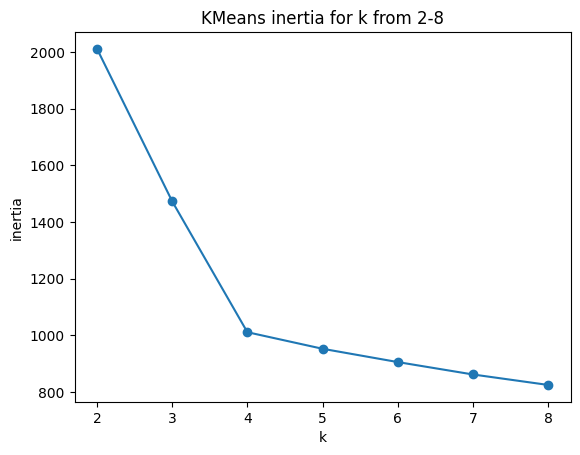

k=2 to k=3: 26.77%
k=3 to k=4: 31.36%
k=4 to k=5: 5.79%
k=5 to k=6: 4.93%
k=6 to k=7: 4.83%
k=7 to k=8: 4.29%


In [117]:
# YOUR CODE
inertias = {}

for k in range(2,9):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = kmeans.fit(X)
    inertias[k] = labels.inertia_
    print(f"k={k}, inertia = {labels.inertia_:.2f}")

# plot
plt.plot(list(inertias.keys()), list(inertias.values()), marker="o")
plt.xlabel("k")
plt.ylabel("inertia")
plt.title("KMeans inertia for k from 2-8")
plt.show()

for key, value in inertias.items():
    if key == 8:
        continue
    reduction = (value - inertias[key + 1]) / value * 100 # percentage reduction in inertia of current to next inertia
    print(f"k={key} to k={key + 1}: {reduction:.2f}%")




>**YOUR ANSWER (Q2.4):** The curve shows a steep decrease in inertia from k = 2 to 4, followed by much smaller decreases from k = 4 to 8. I would place the elbow at k = 4 because it is the point where the reduction in inertia begins to level off. Adding more clusters beyond k = 4 provides only small improvements. The percent reductions support my choice of k because after the reduction of k = 3 to 4 (31.36%),  the reductions after this point are all less than 6%. The main limitation of the elbow method when choosing the number of clusters is that the elbow point can be difficult to identify because the point may be hard to identify on the curve as the curve might not always have a distinct bend like we have at k = 4.
>
>

### Question 3. The silhouette score (3 + 3 + 5 = 11 points)

1. For each value of `k` from 2 to 8, fit k-means on the scaled data `X` with `n_init=10` and `random_state=RANDOM_STATE`, then compute the **silhouette score** using the resulting cluster labels.
2. Plot the silhouette score against `k`, using markers at each data point. Label both axes and add a descriptive title. Report which value of `k` gives the highest silhouette score, and mark it on the plot with a dashed vertical line and an appropriate legend entry.
3. In the answer cell, address the following:
   - In your own words, what does the **silhouette coefficient** measure for an individual point? What do values close to +1, 0, and −1 indicate? How is the overall **silhouette score** calculated from the individual coefficients?
   - Which value of `k` is preferred by the silhouette score? Does it agree with your choice from the elbow method?
   - The second-highest silhouette score is close to the highest. What does that tell you about the choice of `k`, and how would you decide between the two?

k=2, silhouette score = 0.42
k=3, silhouette score = 0.37
k=4, silhouette score = 0.44
k=5, silhouette score = 0.35
k=6, silhouette score = 0.25
k=7, silhouette score = 0.21
k=8, silhouette score = 0.21


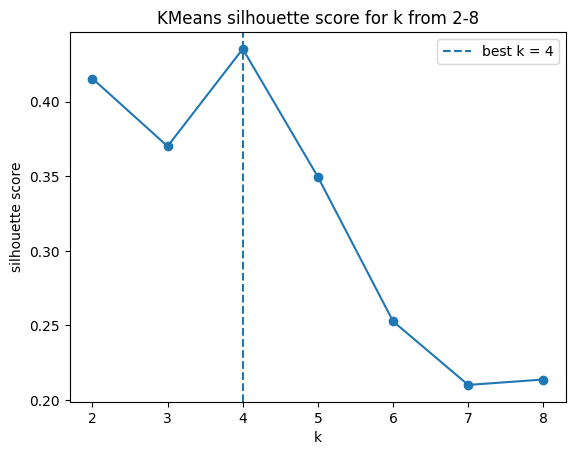

In [118]:
# YOUR CODE
from sklearn.metrics import silhouette_score

silhouette = {}
for k in range(2,9):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = kmeans.fit_predict(X)
    silhouette[k] = silhouette_score(X, labels)
    print(f"k={k}, silhouette score = {silhouette[k]:.2f}")

best_k = max(silhouette, key=silhouette.get) # k value of largest silhouette score



plt.plot(list(silhouette.keys()), list(silhouette.values()), marker="o")
plt.axvline(best_k, linestyle="--", label=f"best k = {best_k}")
plt.xlabel("k")
plt.ylabel("silhouette score")
plt.title("KMeans silhouette score for k from 2-8")
plt.legend()
plt.show()

>**YOUR ANSWER (Q3.3):** The silhouette score measures how well a data point fits into it's assigned cluster. Values closer to +1 indicates that the data point fits well into it's assigned cluster and far from other clusters. Values close to 0 means that the data point is near the boundary between 2 clusters, and values close to -1 means that the data point might be assigned to the wrong cluster because its close to another cluster. The overall silhouette score is calculated by taking the average of all individual data points silhouette coefficients. K = 4 is preferred by the silhouette score and this agrees with my choice from the elbow method. Since the second highest silhouette score is close to the highest, this tells me that both values of k produce similarly good clusters, so there may not be one clearly best choice. To decide between the two, I would compare how clearly separated the clusters are and check whether the clusters have reasonable sizes.
>
>

### Question 4. What happens without scaling (4 + 4 + 4 = 12 points)

In Part 1, you predicted that without scaling, differences in `pop_density` would dominate the distance calculations. Now test that prediction.

1. Repeat the silhouette sweep from Question 3 on the **unscaled** matrix `X_raw`, for each `k` from 2 to 8, using `n_init=10` and `random_state=RANDOM_STATE`.  Display the unscaled and scaled silhouette scores side by side in a single table. Report which value of `k` gives the highest silhouette score for each dataset.
2. Fit k-means with `k=2` on `X_raw`, and report the size of each cluster. For each cluster, calculate and display the **median of every feature in its original units**.
   - Hint: You can use `.median()` from either NumPy or Pandas.
3. In the answer cell, address the following:
   - Compare the highest silhouette score obtained without scaling with the highest score obtained after scaling. Which is higher?
   - Looking at the cluster medians, what distinguishes the two unscaled clusters? Are the differences spread across several features, or are they driven primarily by one feature?
   - This is the most important question in the assignment: If the silhouette score is **higher without scaling**, why might scaling still be the better choice? What does this tell you about the limitations of the silhouette score as a measure of clustering quality?

In [119]:
# YOUR CODE
silhouette_unscaled  = {}

# raw silhouette calculation
for k in range(2,9):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = kmeans.fit_predict(X_raw)
    silhouette_unscaled [k] = silhouette_score(X_raw, labels)

# comparison dataframe
comparison = pd.DataFrame({
    "Scaled": silhouette,
    "Unscaled": silhouette_unscaled,
})

display(comparison)

print("Best k, scaled:", max(silhouette, key=silhouette.get))
print("Best k, unscaled:", max(silhouette_unscaled, key=silhouette_unscaled.get))

kmeans_raw = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE)
labels_raw = kmeans_raw.fit_predict(X_raw)

raw_df = pd.DataFrame(X_raw, columns=features) # dataframe containing the original unscaled features and cluster assignments
raw_df["cluster"] = labels_raw

print(raw_df["cluster"].value_counts().sort_index()) # display the number of data points assigned to each cluster
display(raw_df.groupby("cluster")[features].median()) # display the median value of each feature for each cluster

,Scaled,Unscaled
2,0.415573,0.829103
3,0.370128,0.759580
4,0.435444,0.621560
5,0.349599,0.626155
6,0.252714,0.634800
7,0.210052,0.598691
8,0.213679,0.584679


Best k, scaled: 4
Best k, unscaled: 2
cluster
0    322
1    118
Name: count, dtype: int64


,median_income_k,median_age,pct_rentals,dist_downtown_km,elevation_m,annual_rainfall_in,pct_green_space,pop_density
cluster,,,,,,,,
0,94.65,45.0,29.15,28.75,48.00,30.85,32.0,2688.5
1,67.80,36.7,69.15,2.75,10.85,22.85,8.6,14301.0


3. In the answer cell, address the following:
   - Compare the highest silhouette score obtained without scaling with the highest score obtained after scaling. Which is higher?
   - Looking at the cluster medians, what distinguishes the two unscaled clusters? Are the differences spread across several features, or are they driven primarily by one feature?
   - This is the most important question in the assignment: If the silhouette score is **higher without scaling**, why might scaling still be the better choice? What does this tell you about the limitations of the silhouette score as a measure of clustering quality?

>**YOUR ANSWER (Q4.3):** The unscaled silhouette score is higher. The highest unscaled silhouette score is 0.829 at k = 2 and the highest scaled score is 0.435 at k = 4. The main feature that distinguishes the two unscaled clusters is pop_density. Cluster 0 has a median density of 2688.5 and cluster 1 has a median density of 14301.0. The difference in other features are not nearly as extreme, but we still observe small differences. So the unscaled clusters are mainly distinguished by the pop_density feature. Even though the sillhouette score is higher without scaling, scaling is still the better choice because the higher unscaled score reflects almost entirely pop_density. Scaling prevents features with larger numerical values from dominating the clustering process. This allows all features to contribute more equally, even though the scaled score, 0.435, is much lower than the unscaled score, 0.829. This tells me that the silhouette score has limitations because it only measures cluster separation and compactness and does not consider whether the clusters are meaningful or whether all features are being weighted fairly.

***
## Part 3: Hierarchical Clustering, DBSCAN, and What the Clusters Mean (39 points)

k-means is not the only way to group the data, and it makes assumptions about the shape and structure of clusters that other algorithms do not share. In this part, you will try two alternative approaches — hierarchical clustering and DBSCAN — and explore how their results differ from k-means. Finally, you will compare the clusters discovered by all three algorithms against the `archetype` labels we have been holding back.

### Question 1. Hierarchical clustering and the choice of linkage (3 + 3 + 5 = 11 points)

1. Fit `AgglomerativeClustering` on the scaled data `X` with `n_clusters=4`, using each of the four linkage methods: `"ward"`, `"complete"`, `"average"` and `"single"`. For each method, report the **cluster sizes** and the **silhouette score**.
2. Draw a **dendrogram** of the data using Ward linkage, truncated to the last 20 merges to keep it readable. Label both axes appropriately and add a descriptive title. 
   - Hint: `from scipy.cluster.hierarchy import dendrogram, linkage`, then `Z = linkage(X, method="ward")` and `dendrogram(Z, truncate_mode="lastp", p=20)`.
3. In the answer cell, address the following:
   - Which linkage methods produce reasonably balanced and meaningful clusters, and which one produces a highly unbalanced result? Describe how this shows up in the cluster sizes.
   - Explain *why* that linkage method produces highly unbalanced result, in terms of how it measures the distance between two clusters.
   - What does each tick label on the x-axis of the dendrogram you generated in Question 1.2 represent? What does the y-axis measure, and what do the heights at which branches merge tell us about the similarity between clusters?
   - What does the dendrogram suggest about the number of clusters? How does this compare with your choice in Part 2?

ward: silhouette score = 0.43
0    130
1    120
2     98
3     92
Name: count, dtype: int64

complete: silhouette score = 0.43
0     97
1    120
2     92
3    131
Name: count, dtype: int64

average: silhouette score = 0.43
0    128
1     94
2     98
3    120
Name: count, dtype: int64

single: silhouette score = 0.14
0    318
1    120
2      1
3      1
Name: count, dtype: int64



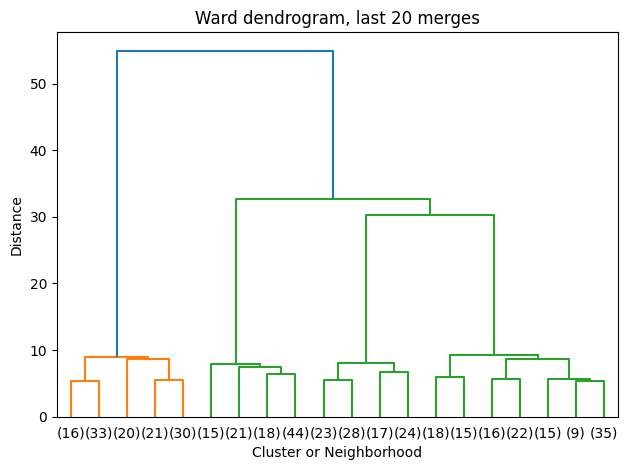

In [120]:
# YOUR CODE
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

linkageMethods = ["ward", "complete", "average", "single"] # 4 linkages we use

for l in linkageMethods:
    agg_cluster = AgglomerativeClustering(n_clusters=4, linkage=l)
    labels = agg_cluster.fit_predict(X)
    sizes = pd.Series(labels).value_counts().sort_index()
    score = silhouette_score(X, labels)
    print(f"{l}: silhouette score = {score:.2f}")
    print(sizes)
    print()

# plot
Z = linkage(X, method="ward")
dendrogram(Z, truncate_mode="lastp", p=20, leaf_font_size=10,)
plt.xlabel("Cluster or Neighborhood")
plt.ylabel("Distance")
plt.title("Ward dendrogram, last 20 merges")
plt.tight_layout()
plt.show()


3. In the answer cell, address the following:
   - Which linkage methods produce reasonably balanced and meaningful clusters, and which one produces a highly unbalanced result? Describe how this shows up in the cluster sizes.
   - Explain *why* that linkage method produces highly unbalanced result, in terms of how it measures the distance between two clusters.
   - What does each tick label on the x-axis of the dendrogram you generated in Question 1.2 represent? What does the y-axis measure, and what do the heights at which branches merge tell us about the similarity between clusters?
   - What does the dendrogram suggest about the number of clusters? How does this compare with your choice in Part 2?

>**YOUR ANSWER (Q1.3):** Ward, complete, and average produce reasonably balanced and meaningful clusters. Each of their four groups has about 90 to 130 neighborhoods, and each has a silhouette score of about 0.43. The single linkage method is highly unbalanced with 318 neighborhoods in one cluster, 120 in another, and the last 2 with 1 neighborhood each. Single linkage measures the distance between two clusters as the distance between their closest pair of points. One nearby point is enough to merge a whole group into a larger one, so clusters grow by chaining. Each x-axis tick is one of the last 20 groups in the ward tree, a label such as (16) means that branch already contains 16 neighborhoods. The y-axis is the Ward distance between the two groups being merged. A low merge means the groups are similar, and a high merge means they were far apart. The largest height jumps are among the final merges, which suggests a small number of clusters. That agrees with the elbow and silhouette results in Part 2, which both pointed to k = 4.
>
>

### Question 2. DBSCAN (3 + 3 + 4 = 10 points)

DBSCAN takes a different approach: instead of being told how many clusters to find, it identifies clusters as dense regions of observations and labels observations that do not belong to any cluster as noise.

1. Run `DBSCAN` on the scaled data `X` with `min_samples=5`, for `eps` values of `0.8, 1.0, 1.2, 1.5, 1.8` and `2.0`. For each value, report the **number of clusters found** (excluding noise) and the **number of noise points**.
   - Hint: Noise points are labelled `-1`, so `len(set(labels) - {-1})` counts the clusters.
2. Choose a **suitable** value of `eps`, refit `DBSCAN`, and report the size of each cluster, including the noise group. Briefly justify your choice.
3. In the answer cell, address the following:
   - Describe what happens as `eps` increases from too small to too large. How do the number of clusters and noise points change?
   - DBSCAN finds clusters without being told how many to look for. Is this an advantage over k-means? What do you have to specify instead?
   - DBSCAN labels some neighborhoods as noise. Is this a weakness or a feature? Explain.

In [121]:
# YOUR CODE
from sklearn.cluster import DBSCAN

epsVal = [0.8, 1.0, 1.2, 1.5, 1.8, 2.0]

for val in epsVal:
    db_scan = DBSCAN(eps=val, min_samples=5)
    labels = db_scan.fit_predict(X)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0) # calculating number of clusters excluding noise
    n_noise = np.sum(labels == -1) # summing labels for number of noise points
    print(f"eps={val}: clusters={n_clusters}, noise points={n_noise}")

"""
use eps=1.2 because that's when it gives a reasonable number of clusters without an enormous number of noise points. The larger eps
(1.5, 1.8, 2.0) results in 2, 1, 1 cluster respectively, which might be too few clusters.
"""
db_scan_suitable = DBSCAN(eps=1.2, min_samples=5)
labels_suitable = db_scan_suitable.fit_predict(X)

print()
print("eps = 1.2 cluster sizes")
print(pd.Series(labels_suitable).value_counts().sort_index()) # finding the number of data points in each cluster



eps=0.8: clusters=7, noise points=375
eps=1.0: clusters=6, noise points=196
eps=1.2: clusters=4, noise points=51
eps=1.5: clusters=2, noise points=7
eps=1.8: clusters=1, noise points=0
eps=2.0: clusters=1, noise points=0

eps = 1.2 cluster sizes
-1     51
 0     81
 1     80
 2    106
 3    122
Name: count, dtype: int64


>**YOUR ANSWER (Q2.3):** When the radius of the neighborhood increases, points that were too far apart start to become neighbors. As a result, the number of clusters and noise points decrease. Finding the clusters without being told how many to look for is advantage over k-means because it means we don't have to specify the number of clusters before hand, instead, with DBSCAN, we have to specify eps, which is the neighborhood radius and min_samples, which is the minimum number of points needed to classify a point as a core point and form a dense region. Labeling some points as noise is a feature because DBSCAN can identify outliers that do not belong to any dense cluster instead of forcing every data point into a cluster. This makes the model useful for finding unusual data points and handling noise in a dataset.
>
>

### Question 3. What are the clusters? (4 + 4 = 8 points)

You may now use the `archetype` column.

1. For each of the following clustering results, create a **frequency table (contingency table)** showing the number of samples from each `archetype` category in each cluster:
   - k-means clustering  with `k=4` on the scaled data
   - Ward clustering
   - DBSCAN with `eps=1.2`.<br><br>

   Hint: Use `pd.crosstab()` to create the table.
2. In the answer cell, address the following:
   - How well do the discovered clusters match the true archetypes?
   - Based on the frequency tables, how do the three algorithms compare?

In [122]:
# YOUR CODE

kmeans_labels = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit_predict(X) # kmeans clustering with 4 clusters and assign labels to each data point
ward_labels = AgglomerativeClustering(n_clusters=4, linkage="ward").fit_predict(X) # hierarchical clustering using Ward's linkage with 4 clusters
dbscan_labels = DBSCAN(eps=1.2, min_samples=5).fit_predict(X) # DBSCAN clustering using eps=1.2 and min_samples=5

# cross tab tables that compare each model with the true archetype labels
print("K-means")
display(pd.crosstab(kmeans_labels, hoods[TRUE_LABEL], rownames=["cluster"], colnames=["archetype"]))

print("Ward")
display(pd.crosstab(ward_labels, hoods[TRUE_LABEL], rownames=["cluster"], colnames=["archetype"]))

print("DBSCAN")
display(pd.crosstab(dbscan_labels, hoods[TRUE_LABEL], rownames=["cluster"], colnames=["archetype"]))

K-means


archetype,resort_coast,suburban,urban_core,windward_rural
cluster,,,,
0,90,0,0,0
1,0,0,120,0
2,0,130,0,1
3,0,0,0,99


Ward


archetype,resort_coast,suburban,urban_core,windward_rural
cluster,,,,
0,0,129,0,1
1,0,0,120,0
2,0,0,0,98
3,90,1,0,1


DBSCAN


archetype,resort_coast,suburban,urban_core,windward_rural
cluster,,,,
-1,10,8,14,19
0,0,0,0,81
1,80,0,0,0
2,0,0,106,0
3,0,122,0,0


2. In the answer cell, address the following:
   - How well do the discovered clusters match the true archetypes?
   - Based on the frequency tables, how do the three algorithms compare?

>**YOUR ANSWER (Q3.2):** KMeans and Ward both perform very well in clustering archetypes into distinct clusters. All 4 clusters in KMeans perform nearly perfectly, with one mistake, which is 1 windward_rural point being clustered with 130 suburban points in cluster 2. Ward is similar aswell, except it was 1 windward_rural being clustered with 129 suburban points in cluster 0 and 1 windward_rural + 1 suburban data point being clustered with 90 resort_coast points in cluster 3. Overall, both performing relatively well. DBSCAN finds the same four groups, and each non-noise cluster is pure, with 81 windward_rural, in cluster 0, 80 resort_coast in cluster 1, 106 urban_core in cluster 2, and 122 suburban in cluster 3. DBSCAN also has a noise cluster, there are a total of 51 points (10 resort_coat + 8 suburban + 14 urban_core + 19 windward_rural) that are being left as noise. Overall, KMeans and ward assigns every data point and is almost perfect in assignment, while DBSCAN clusters are perfectly pure, but it doesn't label the data points that sit between dense groups. 
>
>

### Question 4. What would you tell the planning office? (10 points)

Imagine that the Honolulu City Planning Office wants to use a clustering approach like the one you used to group neighborhoods for service planning — for example, to decide where to target bus routes, park maintenance, or housing programs.

Write **250–400 words** in plain language for a city planner. Do not include code or use technical jargon without explaining it. Address all of the following:

1. **What you did and what you found:** How many groups did you identify, and what characterizes them?
2. **Choosing the number of groups:** How did you decide how many groups to use, and why did this decision involve judgment rather than simply applying a formula?
3. **An important technical choice:** Describe one technical choice that had a substantial impact on your results, explaining its importance in terms a non-specialist would understand.
4. **Limitations:** What conclusions would you avoid drawing from these results? What should the planning office be cautious about?
5. **Next steps:** Identify one specific thing you would do next and explain why you expect it to help.

>**YOUR ANSWER:** I grouped the 440 neighborhoods using median_income_k, median_age, pct_rentals, dist_downtown_km, elevation_m, annual_rainfall_in, pct_green_space, and pop_density. I did not use the archetype labels to form the groups. The neighborhoods split into 4 groups, and those groups match resort_coast, suburban, urban_core, and windward_rural. KMeans had only 1 mistake, and ward had 3. DBSCAN finds the same 4 groups, and each non-noise cluster is pure, but it leaves 51 neighborhoods as noise because they do not sit clearly inside one group.
>
> I chose 4 groups by trying k from 2 to 8. Inertia measures how spread out the neighborhoods are inside their groups. It drops 31.36% from k = 3 to 4, and after that each extra group only reduces inertia by less than 6%. The silhouette score measures how cleanly the groups separate, and it is also highest at k = 4 (0.44), with k = 2 close behind (0.42). Both checks point to 4, but this is still a judgment. The elbow is not always a sharp corner, and the two silhouette scores are close enough that someone could choose 2 if they only wanted a coarse split.
>
> The choice that changed the result was scaling. pop_density runs from about 471 to about 20255, while median_age and annual_rainfall_in are much smaller numbers. Without scaling, the best silhouette score is 0.829 at k = 2, and the two clusters are mostly split by pop_density, with medians of 2688.5 and 14301.0. After scaling, the best score is 0.435 at k = 4. The unscaled score is higher because pop_density dominates the distances. Scaling is still better because the other columns, like median_income_k and dist_downtown_km, get to count.
>
> However, I would avoid assuming that these groups should directly determine where bus routes, park maintenance, or housing programs are needed because the dataset is synthetic, meaning it does not represent actual neighborhoods. Also, neighborhoods near the boundaries between groups may share characteristics with multiple groups
>
> Next, I would rerun this on real census data for actual Oahu neighborhoods and check a sample of the assignments with the planning office. That would show whether the same 4 groups still show up, and which neighborhoods need a closer look before any service decision.
>